# 15 — Why does the CNN beat the matched-filter bank? (ablation)

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Tests three explanations of the CNN's advantage over the sine-Gaussian bank (extension 33), always at the same thresholds-from-validation convention (notebook 12) and with bootstrap errors:

1. **Real noise or detection power?** Same bank and same CNN (already trained on real noise, not retrained) evaluated in **synthetic Gaussian noise** with its own Gaussian background. If the CNN advantage is only about glitch handling it should vanish; if it persists the CNN is simply a better statistic for these signal families.
2. **A richer bank?** A bank with 4× more templates (640: 80 centre frequencies × 8 quality factors). If the gap closes, the advantage was template coverage.
3. **A glitch veto?** The 160-template bank with the simplest veto: discard windows whose largest whitened sample exceeds the 99.5 % quantile of the validation noise.

**What it does not do.** It does not retrain the CNN in Gaussian noise (so the Gaussian result also tests transfer to noise it never saw), it does not test a chi² veto (extension 18) or bank optimisation (extension 40), and the veto is deliberately crude.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seq_models as sm
import gwosc_tools as g
g.style()
tf, keras, L = sm._tf()
rng = np.random.default_rng(15)
CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
V, ID = {}, {}
for sp in ("val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
S1 = {sp: np.stack([CH[i]["S1"] for i in ID[sp]]) for sp in V}
NETS = [sm.train_variant("cnn_fresh", None, None, seed=s, verbose=False)[0] for s in (0, 1)]       # cached by notebook 07
logit = lambda v: np.mean([m.predict(sm.clip(v)[..., None], verbose=0, batch_size=1024)[:, 0] for m in NETS], 0)
SNRS = [3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16]; NINJ = 300
B160 = {i: g.SGBank(CH[i]["S1"]) for i in CH}
B640 = {i: g.SGBank(CH[i]["S1"], f0s=np.geomspace(40, 450, 80), Qs=[2, 3, 4.5, 6, 8, 10, 13, 16]) for i in CH}
print(len(B160[0].grid), "and", len(B640[0].grid), "templates")

160 and 640 templates


## 1. Real noise: background and injections

In [2]:
def real_stats(v, cid):
    return dict(b160=g.scan_mixed(v, cid, B160)["rho2"], b640=g.scan_mixed(v, cid, B640)["rho2"], cnn=logit(v), vmax=np.abs(v).max(1))
fn = os.path.join(g.CACHE, "stats15.pkl")
import pickle
if os.path.exists(fn):
    ST = pickle.load(open(fn, "rb"))
else:
    t0_ = time.time(); ST = {"real_val": real_stats(V["val"], ID["val"])}
    for kind in g.MORPHS:
        for snr in SNRS:
            idx = rng.choice(len(V["test"]), NINJ, replace=False)
            ser, _, _ = g.inject(V["test"][idx], kind, float(snr), rng, S1["test"][idx])
            ST[(kind, snr)] = real_stats(ser, ID["test"][idx])
    pickle.dump(ST, open(fn, "wb")); print("real-noise scans: %.0f s" % (time.time() - t0_))
print(len(ST), "sets")

real-noise scans: 158 s
34 sets


## 2. Gaussian noise: the same detectors, ideal noise

In [3]:
fn = os.path.join(g.CACHE, "stats15_gauss.pkl")
S1g = CH[3]["S1"]; BG = g.SGBank(S1g)
def gauss_windows(n): return g.to_series((rng.normal(size=(n, g.NB)) + 1j * rng.normal(size=(n, g.NB))) * g.BAND)
def gauss_stats(v): return dict(b160=BG.scan(g.to_bins(v))["rho2"], cnn=logit(v))
if os.path.exists(fn):
    STG = pickle.load(open(fn, "rb"))
else:
    STG = {"val": gauss_stats(gauss_windows(16224))}
    for kind in g.MORPHS:
        for snr in SNRS:
            ser, _, _ = g.inject(gauss_windows(NINJ), kind, float(snr), rng, S1g); STG[(kind, snr)] = gauss_stats(ser)
    pickle.dump(STG, open(fn, "wb"))
print(len(STG), "sets")

34 sets


## 3. rho50 with bootstrap errors

In [4]:
vcut = np.quantile(ST["real_val"]["vmax"], 0.995)
def veto(d, key="b160"): return np.where(d["vmax"] > vcut, 0.0, d[key])
cases = {  # label: (background array, function d -> statistic)
    "bank 160 (real noise)": (ST, ST["real_val"], lambda d: d["b160"]),
    "bank 640 (real noise)": (ST, ST["real_val"], lambda d: d["b640"]),
    "bank 160 + amplitude veto (real noise)": (ST, ST["real_val"], veto),
    "CNN fresh (real noise)": (ST, ST["real_val"], lambda d: d["cnn"]),
    "bank 160 (Gaussian noise)": (STG, STG["val"], lambda d: d["b160"]),
    "CNN fresh (Gaussian noise)": (STG, STG["val"], lambda d: d["cnn"]),
}
rows = []
for lab, (D, bk, f) in cases.items():
    for far in (1e-2, 1e-3):
        for kind in g.MORPHS:
            p, b = g.bootstrap_rho(f(bk), [f(D[(kind, s)]) for s in SNRS], SNRS, far, B=200, seed=5)
            rows.append(dict(case=lab, FAP=far, morph=kind, rho50=p[0], err=(g.ci(b[:, 0])[1] - g.ci(b[:, 0])[0]) / 2))
R = pd.DataFrame(rows)
T = R.pivot_table(index="case", columns=["FAP", "morph"], values="rho50"); T[("mean", 1e-2)] = T[1e-2].mean(1); T[("mean", 1e-3)] = T[1e-3].mean(1)
print("fraction of validation noise vetoed: %.4f ; of injected sg rho=8 windows: %.3f" % ((ST["real_val"]["vmax"] > vcut).mean(), (ST[("sg", 8)]["vmax"] > vcut).mean()))
T.round(2)

fraction of validation noise vetoed: 0.0051 ; of injected sg rho=8 windows: 0.173


FAP                                    0.001              0.01              \
morph                                  chirp pulse    sg chirp pulse    sg   
case                                                                         
CNN fresh (Gaussian noise)              6.90  5.58  6.43  6.10  4.91  5.88   
CNN fresh (real noise)                  5.78  4.81  5.86  4.60  4.13  4.77   
bank 160 (Gaussian noise)               6.91  5.83  5.27  6.17  5.18  4.78   
bank 160 (real noise)                   8.84  7.37  6.92  6.34  5.36  5.03   
bank 160 + amplitude veto (real noise)  7.71   NaN  6.02  6.33  5.59  5.06   
bank 640 (real noise)                   8.80  7.14  6.89  6.33  5.25  5.03   

FAP                                     mean        
morph                                   0.01 0.001  
case                                                
CNN fresh (Gaussian noise)              5.63  6.30  
CNN fresh (real noise)                  4.50  5.48  
bank 160 (Gaussian noise)               5.38  6.00  
bank 160 (real noise)                   5.58  7.71  
bank 160 + amplitude veto (real noise)  5.66  6.87  
bank 640 (real noise)                   5.54  7.61

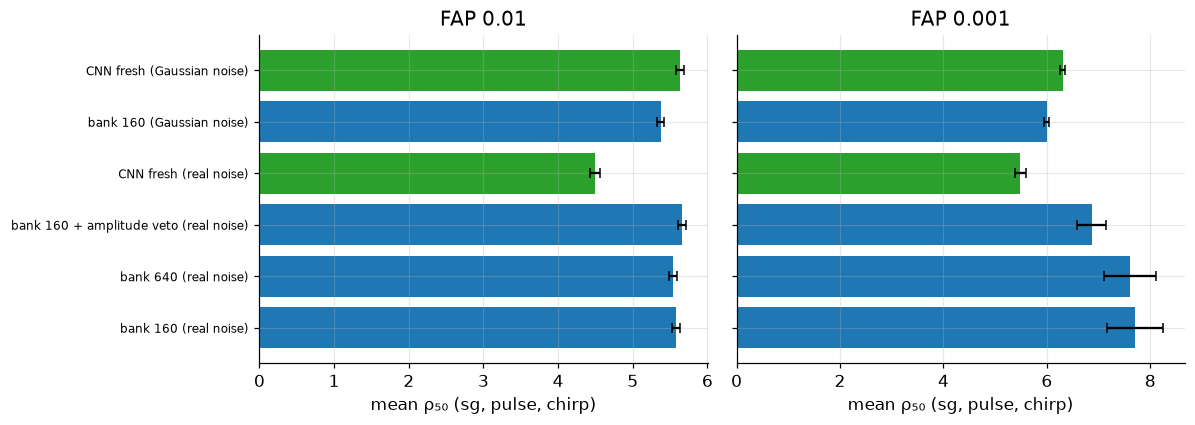

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, far in zip(ax, (1e-2, 1e-3)):
    m = R[R.FAP == far].groupby("case").agg(rho50=("rho50", "mean"), err=("err", lambda e: float(np.sqrt((e ** 2).sum()) / 3)))
    m = m.loc[list(cases)]; a.barh(range(len(m)), m.rho50, xerr=m.err, color=[g.COLORS["freq"] if "bank" in c else g.COLORS["ml"] if "ml" in g.COLORS else "C2" for c in m.index], capsize=3)
    a.set_yticks(range(len(m))); a.set_yticklabels(m.index, fontsize=8); a.invert_yaxis(); a.set_xlabel("mean ρ₅₀ (sg, pulse, chirp)"); a.set_title(f"FAP {far:g}")
fig.tight_layout(); g.savefig(fig, "fig15_ablation"); plt.show()
g.save_json(dict(rows=R.to_dict("records"), veto_cut=float(vcut)), "15_summary.json")

## Output and next step

`results/15_summary.json`, `figures/fig15_ablation`. Next: signal-consistency vetoes and a combined ranking statistic for the bank (extensions 18 and 39).